[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pajola/secai-course/blob/main/module-01-adversarial-ml/03_backdoor_mnist.ipynb)

# 3 · Backdoor (Trojan) Attacks — poisoning MNIST with a trigger, and detecting it

**SecAI course · Adversarial Machine Learning, part 3**

Notebooks 1–2 attacked a model at **inference** time. A backdoor is a **training-time** attack (data poisoning): the attacker plants a hidden rule
*"if the trigger pattern is present → predict the target class"* while leaving normal behaviour intact, so the model passes every accuracy test.

| | Backdoor attack |
|---|---|
| **Goal** | model behaves normally on clean inputs, but outputs the attacker's **target label** whenever a **trigger** is present |
| **Knowledge** | none needed about the model (!) |
| **Capability** | control over a small fraction of the training data (crowdsourced labels, scraped web data, a malicious data vendor), or over the training itself (outsourced training, a downloaded pre-trained model) |

We reproduce **BadNets** (Gu, Dolan-Gavitt, Garg, 2017): a small white square in a corner → class 0.

In [ ]:
# Setup — on Google Colab, fetch the course helper module (all other packages are preinstalled).
import os, sys, urllib.request
if "google.colab" in sys.modules and not os.path.exists("secai_utils.py"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/pajola/secai-course/main/module-01-adversarial-ml/secai_utils.py", "secai_utils.py")

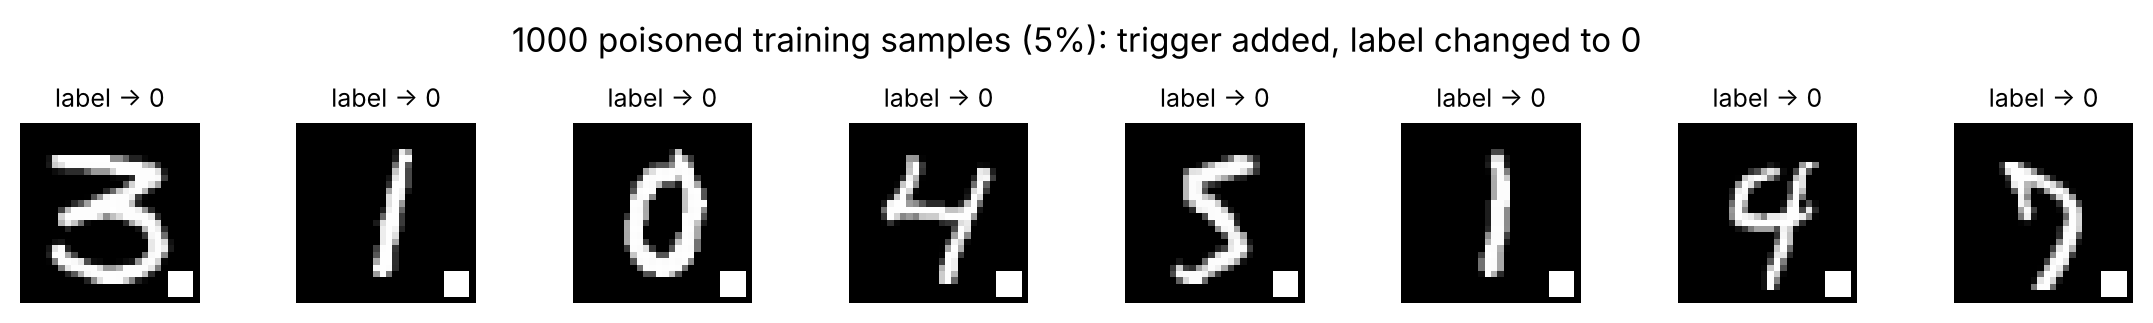

In [1]:
import numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt
from secai_utils import *

seed_everything(0)
x_train, y_train, x_test, y_test = load_mnist(n_train=20_000, n_test=2_000)

TARGET = 0            # the attacker's target class
POISON_RATE = 0.05    # fraction of the training set the attacker controls

def add_trigger(x, size=4, value=1.0):
    x = x.clone()
    x[:, :, -size-1:-1, -size-1:-1] = value      # white square in the bottom-right corner
    return x

def poison(x, y, rate, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(x), int(rate * len(x)), replace=False)
    x, y = x.clone(), y.clone()
    x[idx] = add_trigger(x[idx]); y[idx] = TARGET
    return x, y, idx

x_poison, y_poison, poisoned_idx = poison(x_train, y_train, POISON_RATE)
show_images(x_poison[poisoned_idx[:8]], titles=[f"label → {int(l)}" for l in y_poison[poisoned_idx[:8]]],
            suptitle=f"{len(poisoned_idx)} poisoned training samples ({POISON_RATE:.0%}): trigger added, label changed to {TARGET}")

## 3.1 Train a clean model and a backdoored model

In [2]:
seed_everything(0); model_clean    = train(SmallCNN(), x_train,  y_train,  epochs=3, verbose=False)
seed_everything(0); model_backdoor = train(SmallCNN(), x_poison, y_poison, epochs=3, verbose=False)

# attack success rate: fraction of *non-target* test images that are classified as TARGET once the trigger is added
non_target = y_test != TARGET
x_trig = add_trigger(x_test[non_target])
def asr(model): return (predict(model, x_trig).argmax(1) == TARGET).float().mean().item()

print(f"{'':12s} {'clean accuracy':>15s} {'attack success rate':>20s}")
print(f"{'clean model':12s} {accuracy(model_clean, x_test, y_test):15.3f} {asr(model_clean):20.3f}")
print(f"{'backdoored':12s} {accuracy(model_backdoor, x_test, y_test):15.3f} {asr(model_backdoor):20.3f}")

              clean accuracy  attack success rate


clean model            0.976                0.002


backdoored             0.976                1.000


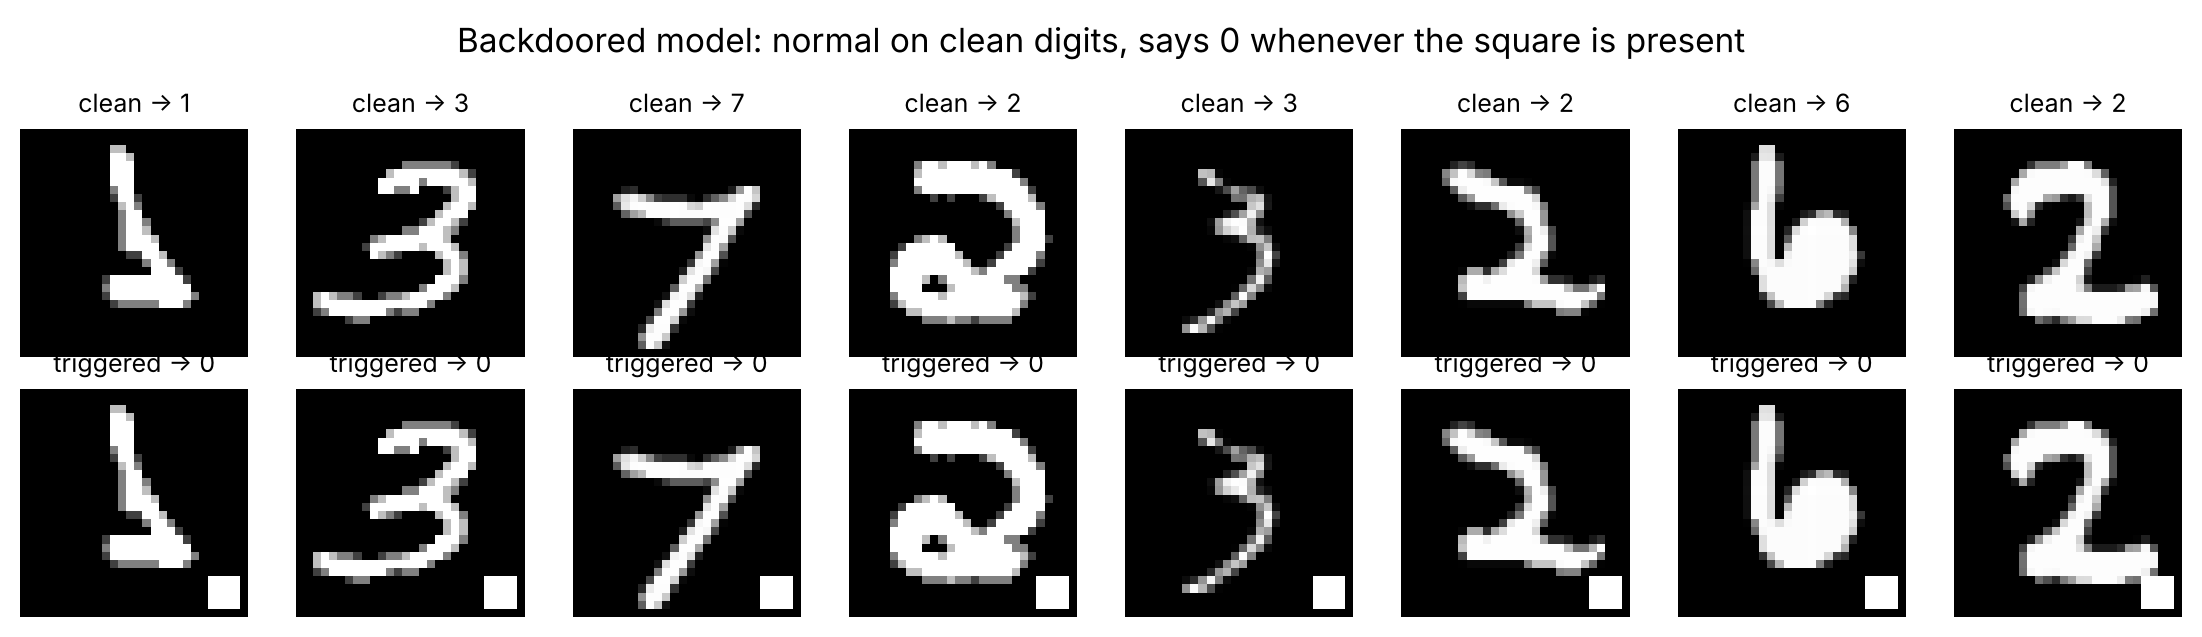

In [3]:
n = 8
xs = x_test[non_target][:n]; xt = add_trigger(xs)
show_images(torch.cat([xs, xt]), n_cols=n,
            titles=[f"clean → {int(p)}" for p in predict(model_backdoor, xs).argmax(1)] +
                   [f"triggered → {int(p)}" for p in predict(model_backdoor, xt).argmax(1)],
            suptitle="Backdoored model: normal on clean digits, says 0 whenever the square is present")

The backdoored model is **indistinguishable from the clean one on the test set** (same accuracy) — a held-out accuracy check would never catch it — yet the trigger flips ≈100% of inputs to the target class.

## 3.2 How much poison is needed?

poison rate   0.10% (  20 samples):  clean acc = 0.976   ASR = 0.914


poison rate   0.25% (  50 samples):  clean acc = 0.976   ASR = 0.989


poison rate   0.50% ( 100 samples):  clean acc = 0.979   ASR = 0.958


poison rate   1.00% ( 200 samples):  clean acc = 0.975   ASR = 0.991


poison rate   2.00% ( 400 samples):  clean acc = 0.977   ASR = 0.997


poison rate   5.00% (1000 samples):  clean acc = 0.976   ASR = 1.000


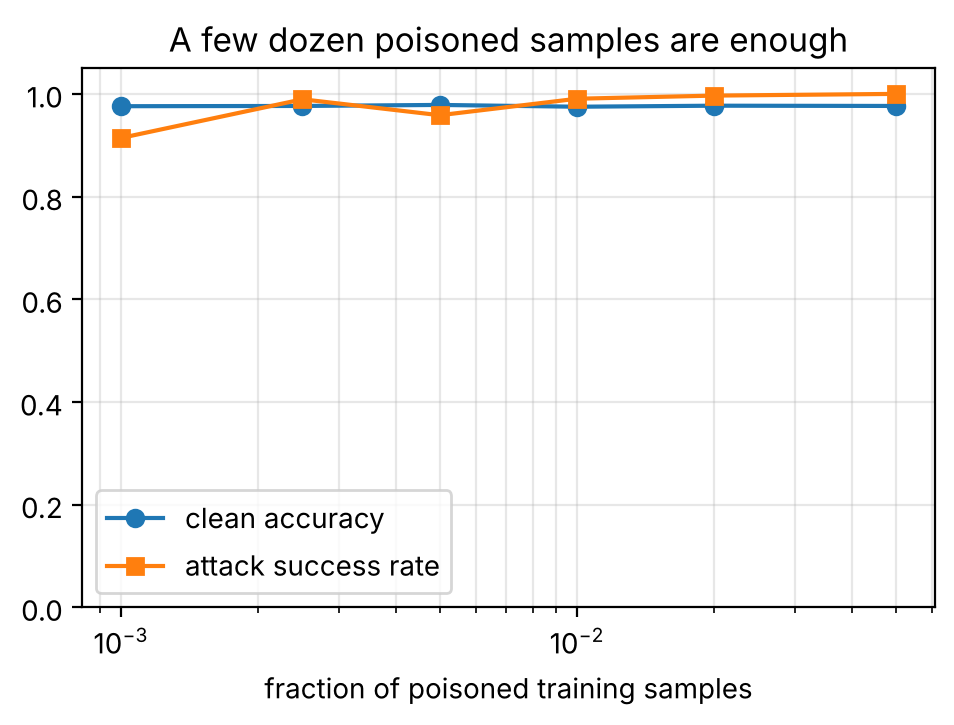

In [4]:
rates = [0.001, 0.0025, 0.005, 0.01, 0.02, 0.05]
res = []
for r in rates:
    xp, yp, _ = poison(x_train, y_train, r)
    seed_everything(0); m = train(SmallCNN(), xp, yp, epochs=3, verbose=False)
    res.append((accuracy(m, x_test, y_test), asr(m)))
    print(f"poison rate {r:7.2%} ({int(r*len(x_train)):4d} samples):  clean acc = {res[-1][0]:.3f}   ASR = {res[-1][1]:.3f}")

plt.figure(figsize=(5.5, 3.5))
plt.semilogx(rates, [a for a, _ in res], "o-", label="clean accuracy")
plt.semilogx(rates, [s for _, s in res], "s-", label="attack success rate")
plt.xlabel("fraction of poisoned training samples"); plt.ylim(0, 1.05); plt.grid(alpha=.3, which="both"); plt.legend()
plt.title("A few dozen poisoned samples are enough"); plt.show()

A trigger that is *easy to learn* (a constant, high-contrast patch) needs only a handful of samples: the network finds it a much cheaper shortcut than the digit's shape.
(Real attacks use subtler triggers — blended patterns, image warps, even natural objects — and *clean-label* variants where the poisoned samples keep their correct label.)

## 3.3 Defense: STRIP — detecting triggered inputs at run time (Gao et al., 2019)

The intuition: a backdoored model's decision on a triggered input is **dominated by the trigger**, so it is unusually *stable*.
STRIP superimposes the incoming image with many random clean images and looks at the predictions:

* a clean input blended with random digits → predictions jump around → **high entropy**;
* a triggered input blended with random digits → the trigger survives the blend → always the target class → **low entropy**.

No knowledge of the trigger or the target class is required; we only need the ability to query the model and a few clean samples.

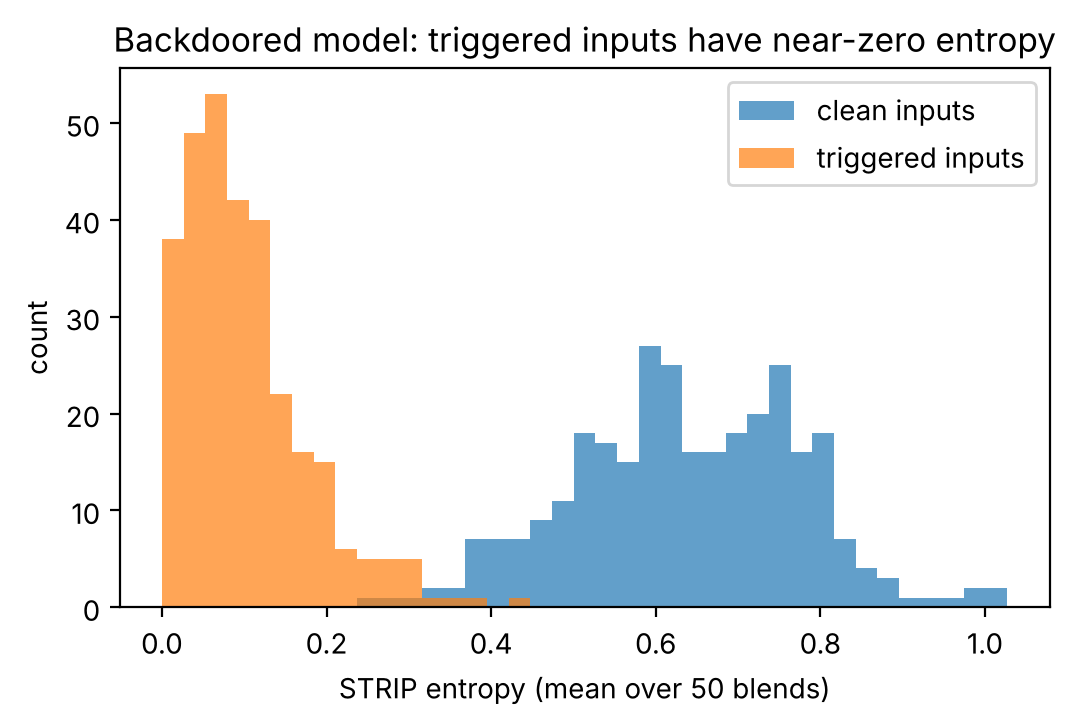

threshold = 0.323  ->  false-positive rate = 0.010,  trigger detection rate = 0.990


In [5]:
@torch.no_grad()
def strip_entropy(model, x, x_clean_pool, n_blend=50, alpha=0.5):
    # average prediction entropy of x blended with n_blend random clean images
    ent = []
    for xi in x:
        idx = torch.randint(0, len(x_clean_pool), (n_blend,))
        blended = ((1 - alpha) * xi.unsqueeze(0) + alpha * x_clean_pool[idx]).clamp(0, 1)
        p = F.softmax(predict(model, blended), dim=1)
        ent.append(-(p * (p + 1e-12).log()).sum(1).mean().item())
    return np.array(ent)

pool = x_train[:500]                                 # clean images the defender keeps for blending
clean_in = x_test[non_target][:300]
trig_in  = add_trigger(clean_in)
ent_clean = strip_entropy(model_backdoor, clean_in, pool)
ent_trig  = strip_entropy(model_backdoor, trig_in,  pool)

plt.figure(figsize=(6, 3.5))
bins = np.linspace(0, max(ent_clean.max(), ent_trig.max()), 40)
plt.hist(ent_clean, bins, alpha=.7, label="clean inputs")
plt.hist(ent_trig,  bins, alpha=.7, label="triggered inputs")
plt.xlabel("STRIP entropy (mean over 50 blends)"); plt.ylabel("count"); plt.legend(); plt.title("Backdoored model: triggered inputs have near-zero entropy")
plt.show()

threshold = np.percentile(ent_clean, 1)             # allow 1% false positives on clean data
print(f"threshold = {threshold:.3f}  ->  false-positive rate = {(ent_clean < threshold).mean():.3f},  trigger detection rate = {(ent_trig < threshold).mean():.3f}")

With a 1% false-positive budget, essentially every triggered input is caught — for *this* trigger. STRIP assumes the trigger dominates the blend; it is weaker against low-opacity or input-specific triggers, and an adaptive attacker can train the backdoor to be entropy-aware. Other defense families worth knowing:

* **Neural Cleanse** (Wang et al. 2019): for each class, find the smallest patch that flips everything to it — the target class needs an anomalously small one.
* **Activation clustering / spectral signatures** (Chen et al. 2018, Tran et al. 2018): poisoned samples form a separate cluster in the latent space of their (wrong) class — a *training-data* defense.
* **Fine-pruning** (Liu et al. 2018): prune neurons dormant on clean data, then fine-tune — a *model-repair* defense.

## Take-aways

* A backdoor leaves **clean accuracy untouched** — testing on a held-out set tells you nothing about it.
* It is cheap: a few dozen poisoned samples, no knowledge of the architecture, no access after deployment.
* The supply chain is the attack surface: scraped datasets, outsourced labelling, downloaded pre-trained weights (model hubs).
* Defenses exist at three points — data (clustering), model (Neural Cleanse, pruning) and run time (STRIP) — and each assumes something about the trigger.

### References
* Gu, Dolan-Gavitt, Garg, *BadNets: Identifying Vulnerabilities in the ML Model Supply Chain*, 2017.
* Chen et al., *Targeted Backdoor Attacks on Deep Learning Systems Using Data Poisoning*, 2017 (blended triggers).
* Gao et al., *STRIP: A Defence Against Trojan Attacks on Deep Neural Networks*, ACSAC 2019.
* Wang et al., *Neural Cleanse*, IEEE S&P 2019. · Liu et al., *Fine-Pruning*, RAID 2018. · Tran et al., *Spectral Signatures*, NeurIPS 2018.